
### Quick-mode prediction experiment

We compare the full 55-feature model with a simplified version
using 15 observed features and historical training defaults for
the remaining 40.

The experiment uses October–December 2015 validation loans.
The model and decision threshold remain unchanged.



In [1]:

from pathlib import Path
from datetime import date
import sys

import numpy as np
import pandas as pd
import polars as pl

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))

from loanrisk.predict import load_model, predict_full

bundle = load_model()
raw_cols = bundle["raw_columns"]
defaults = bundle["historical_defaults"]

quick_cols = [
    "loan_amnt", "int_rate", "purpose", "annual_inc",
    "emp_length", "home_ownership", "addr_state",
    "fico_range_low", "dti", "revol_util", "open_acc",
    "total_acc", "delinq_2yrs", "inq_last_6mths",
    "revol_bal",
]

assert len(raw_cols) == 55
assert len(quick_cols) == 15
assert set(quick_cols).issubset(raw_cols)
assert set(raw_cols).issubset(defaults)

# Load only the validation period
source = root / "data/interim/lendingclub_2013_2016_36m_raw.parquet"

val_df = (
    pl.scan_parquet(source)
    .filter(
        (pl.col("issue_date") >= date(2015, 10, 1))
        & (pl.col("issue_date") < date(2016, 1, 1))
    )
    .select(raw_cols + ["target"])
    .collect()
    .to_pandas()
)

assert len(val_df) == 88810

X_full = val_df[raw_cols].copy()
y_val = val_df["target"].to_numpy()

# Keep the 15 selected features; replace the remaining 40
X_quick = X_full.copy()

omitted_cols = [c for c in raw_cols if c not in quick_cols]

for col in omitted_cols:
    value = defaults[col]
    X_quick[col] = np.nan if pd.isna(value) else value

pd.testing.assert_frame_equal(
    X_full[quick_cols],
    X_quick[quick_cols],
)

print("Validation loans:", len(X_full))
print("Full inputs:", len(raw_cols))
print("Observed Quick inputs:", len(quick_cols))
print("Default-filled inputs:", len(omitted_cols))
print("Quick feature preservation: PASS")
print("2016 holdout untouched.")


Validation loans: 88810
Full inputs: 55
Observed Quick inputs: 15
Default-filled inputs: 40
Quick feature preservation: PASS
2016 holdout untouched.



### Full vs Quick prediction performance

We evaluate the saved XGBoost model using all 55 original features
and then using 15 observed features with 40 historical defaults.

Both versions use the same frozen threshold (0.1561).
We compare ranking performance, classification metrics, and
the effect of replacing missing information with defaults.


In [2]:

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    balanced_accuracy_score,
    brier_score_loss,
)

# Predictions from the same saved model
full_result = predict_full(X_full, bundle)
quick_result = predict_full(X_quick, bundle)

p_full = full_result["default_risk_score"].to_numpy()
p_quick = quick_result["default_risk_score"].to_numpy()

threshold = float(bundle["threshold"])


def evaluate_scores(y_true, scores):
    predictions = (scores >= threshold).astype(int)

    return {
        "PR-AUC": average_precision_score(y_true, scores),
        "ROC-AUC": roc_auc_score(y_true, scores),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_true, predictions
        ),
        "Brier score": brier_score_loss(y_true, scores),
        "Flagged (%)": predictions.mean() * 100,
    }


comparison = pd.DataFrame({
    "Full (55)": evaluate_scores(y_val, p_full),
    "Quick (15)": evaluate_scores(y_val, p_quick),
})

comparison["Quick - Full"] = (
    comparison["Quick (15)"] - comparison["Full (55)"]
)

display(comparison.round(4))

# Compare individual predictions
score_difference = np.abs(p_full - p_quick)

full_flags = p_full >= threshold
quick_flags = p_quick >= threshold

print("Threshold:", round(threshold, 4))
print("Mean absolute score difference:", round(score_difference.mean(), 4))
print("Median absolute score difference:", round(np.median(score_difference), 4))
print("90th percentile score difference:", round(np.percentile(score_difference, 90), 4))
print("Classification agreement:", round((full_flags == quick_flags).mean(), 4))
print("Changed classifications:", int((full_flags != quick_flags).sum()))
print("2016 holdout untouched.")


,Full (55),Quick (15),Quick - Full
PR-AUC,0.2991,0.2734,-0.0257
ROC-AUC,0.7149,0.6935,-0.0215
F1,0.3644,0.3389,-0.0255
Precision,0.2693,0.2646,-0.0046
Recall,0.5637,0.4711,-0.0926
Balanced accuracy,0.6485,0.6215,-0.0271
Brier score,0.1171,0.1200,0.0028
Flagged (%),31.0753,26.4216,-4.6538


Threshold: 0.1561
Mean absolute score difference: 0.0292
Median absolute score difference: 0.0197
90th percentile score difference: 0.0656
Classification agreement: 0.8704
Changed classifications: 11513
2016 holdout untouched.



### Quick-mode ranking and calibration analysis

We examine whether replacing 40 features changes risk rankings,
high-risk loan identification, and score calibration.

This analysis uses late-2015 validation data only.
The saved model and threshold remain unchanged.


Spearman rank correlation: 0.9067
Top 10% risk-group overlap: 0.6579
Mean signed score change: -0.0069
Full high-risk -> Quick low-risk: 7823
Full low-risk -> Quick high-risk: 3690


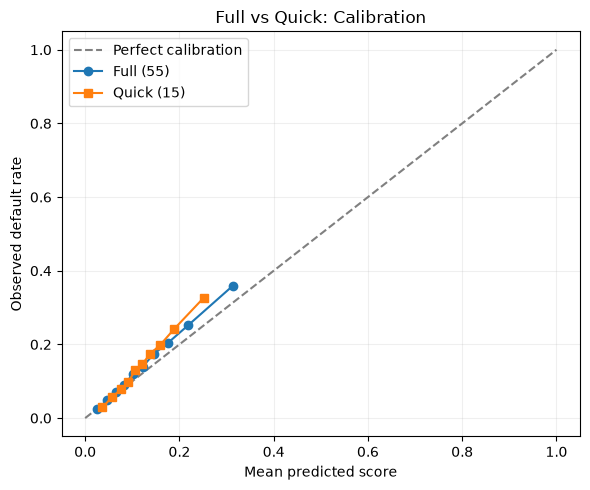

In [3]:

from scipy.stats import spearmanr
import matplotlib.pyplot as plt

# Compare risk-score rankings
rank_corr = spearmanr(p_full, p_quick).statistic

k = int(np.ceil(len(p_full) * 0.10))
top_full = set(np.argpartition(p_full, -k)[-k:])
top_quick = set(np.argpartition(p_quick, -k)[-k:])

top_overlap = len(top_full & top_quick) / k

# Examine direction of score changes
difference = p_quick - p_full

full_flags = p_full >= threshold
quick_flags = p_quick >= threshold

print("Spearman rank correlation:", round(rank_corr, 4))
print("Top 10% risk-group overlap:", round(top_overlap, 4))
print("Mean signed score change:", round(difference.mean(), 4))
print("Full high-risk -> Quick low-risk:", np.sum(full_flags & ~quick_flags))
print("Full low-risk -> Quick high-risk:", np.sum(~full_flags & quick_flags))

# Calibration by predicted-score deciles
def calibration_deciles(y, scores):
    df = pd.DataFrame({"score": scores, "actual": y})
    df["decile"] = pd.qcut(
        df["score"].rank(method="first"),
        q=10,
        labels=False,
    )

    return df.groupby("decile").agg(
        predicted=("score", "mean"),
        observed=("actual", "mean"),
    )

cal_full = calibration_deciles(y_val, p_full)
cal_quick = calibration_deciles(y_val, p_quick)

plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
plt.plot(cal_full["predicted"], cal_full["observed"], "o-", label="Full (55)")
plt.plot(cal_quick["predicted"], cal_quick["observed"], "s-", label="Quick (15)")
plt.xlabel("Mean predicted score")
plt.ylabel("Observed default rate")
plt.title("Full vs Quick: Calibration")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()



### Quick-Mode Validation: Results and Conclusion

We compared the full 55-feature XGBoost model with a simplified 15-feature GUI mode, where the remaining 40 features were filled using training-data medians or modes. Both used the same trained model and threshold (0.1561).

| Metric | Full (55) | Quick (15) |
|---|---:|---:|
| PR-AUC | 0.2991 | 0.2734 |
| ROC-AUC | 0.7149 | 0.6935 |
| F1-score | 0.3644 | 0.3389 |
| Recall | 0.5637 | 0.4711 |
| Brier score | 0.1171 | 0.1200 |

**Additional findings:**
- Spearman correlation: 0.9067, indicating strong overall ranking similarity.
- Top-10% risk-group overlap: 65.79%, showing notable disagreement among high-risk loans.
- Classification agreement: 87.04%, with 11,513 changed classifications.
- Quick mode produces slightly lower scores on average (-0.0069).
- Calibration plots suggest both modes underestimate observed default rates in parts of the score range.

**Conclusion:** Replacing 40 features with historical defaults reduces predictive performance, particularly recall. The full 55-feature model remains our primary approach. The 15-feature mode will be retained only as an experimental GUI demonstration, with its limitations clearly stated. These results are based on late-2015 validation data, not the independent 2016 test set.


In [4]:

import numpy as np
from loanrisk.predict import predict_full

# Take one complete-schema validation record
sample = X_full.iloc[[0]].copy()

# Simulate missing values in existing columns
sample["revol_util"] = np.nan
sample["emp_length"] = np.nan
sample["mths_since_last_delinq"] = np.nan
sample["mths_since_recent_inq"] = np.nan

# Confirm feature preparation preserves missing indicators
prepared = bundle["pipeline"].named_steps["features"].transform(sample)

print("Missing indicators:")
print(prepared[
    [
        "emp_length_missing",
        "delinq_recency_missing",
        "recent_inq_missing",
    ]
])

# Full pipeline handles missing values
result = predict_full(sample, bundle)

assert np.isfinite(result["default_risk_score"]).all()

print("\nMissing-value prediction: PASS")
display(result)


Missing indicators:
   emp_length_missing  delinq_recency_missing  recent_inq_missing
0                   1                       1                   1

Missing-value prediction: PASS


,default_risk_score,predicted_default
0,0.14148,0


In [5]:
print("Original employment length:")
print(sample["emp_length"])

print("\nPrepared employment features:")
display(prepared[
    ["emp_length_years", "emp_length_missing"]
])

Original employment length:
0   NaN
Name: emp_length, dtype: float64

Prepared employment features:


,emp_length_years,emp_length_missing
0,NaN,1
